# State of the art: structural, actuarial and rare-event portfolio models, and the open-source gap

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 06 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- name the families of portfolio credit models in the literature the research found (structural, actuarial, the large-portfolio limit and its granularity adjustment, rare-event simulation) and say which of them Contraste runs and which it does not;
- compare five of them on one book with one calibration, in capital at 99% and 99.9%, and read the ratios the case reports as its impact figures;
- say what Gordy's result on the two families implies for the comparison, and how far this notebook goes in testing it;
- weigh the uncertainty of the correlation input against the choice of model, in capital;
- state the open-source gap the research found, with its date and its limits.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Seven committed files of case C10 (owner: this repository; the loss rates behind the fits come from the Federal Reserve's table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, public domain, licence class `mirror-allowed`):

- the five loan-type files in `data/derived/C10/`, each with the committed ladder of rungs C1 to C6 on the illustrative book of that loan type (a constructed book, never a bank's), the granularity block and the `impact` figures;
- `models-c10.json`: the definition of the ladder, the rungs with their engine function and reference, and the parameters of the case;
- `grid-22.json`: the simulator grid of notebook 06, from which we read the measured size of the correlation interval.

No simulation is rerun here: the full-size Monte Carlo runs are read as committed, and only the analytic rungs are recomputed. The next cell loads the files and prints the ladder as the case defines it.

In [2]:
# Load the files and print the ladder of the case with its engine functions and references
NAMES = {
    "commercial-industrial": "Commercial and industrial",
    "commercial-real-estate": "Commercial real estate",
    "residential": "Residential real estate",
    "credit-cards": "Credit cards",
    "other-consumer": "Other consumer",
}
LANG = "en"
read = lambda name: json.loads((ROOT / "data" / "derived" / "C10" / f"{name}.json").read_text(encoding="utf-8"))
docs = {k: read(k) for k in NAMES}
models = read("models-c10")
grid22 = read("grid-22")
print("baked by riskvalidation", {d["provenance"]["riskvalidation_version"] for d in docs.values()})
print(f"{'rung':6s} {'method':30s} {'estimator':12s} engine function")
for row in models["fit"]["ladder"]:
    print(f"{row['rung']:6s} {row['method']:30s} {row['estimator']:12s} {row['engine_function'].replace('riskvalidation.', '')}")

baked by riskvalidation {'0.7.0'}
rung   method                         estimator    engine function
C1     lhp-vasicek                    analytic     portfolio.portfolio.lhp_measures
C2     gaussian-copula-one-factor     monte-carlo  portfolio.copula.simulate_gaussian
C2     gaussian-copula-multi-factor   monte-carlo  portfolio.copula.simulate_gaussian
C3     student-t-copula               monte-carlo  portfolio.copula.simulate_student_t
C4     creditrisk-plus                analytic     portfolio.creditrisk_plus.pmf_stable
C5     granularity-adjustment         analytic     portfolio.granularity.granularity_adjustment
C6     importance-sampling            monte-carlo  portfolio.importance.importance_sample_gaussian
C6     importance-sampling            monte-carlo  portfolio.importance.importance_sample_gaussian


## Method

The comparison is built so that the models differ in one thing, their structure, and nothing else. Every rung of the ladder takes **the same book** (three groups of identical names, 1,120 names, 100 million USD, LGD 45%), **the same PD and correlation** (the maximum-likelihood fit of notebook 02), and the same quantile levels. What each rung changes:

| Rung | Model | Change from the one above |
|---|---|---|
| C1 | large homogeneous portfolio | the closed-form limit: infinitely many names, one factor |
| C2 | Gaussian copula, one factor | the finite book, simulated |
| C2 | Gaussian copula, two sectors | two correlated sector factors instead of one |
| C3 | Student t copula, 5 degrees of freedom | tail dependence |
| C4 | CreditRisk+, stable recursion | an actuarial model with a Gamma factor, solved exactly |
| C5 | large-portfolio limit plus the granularity adjustment | the closed-form limit, corrected for concentration |
| C6 | importance sampling, Gaussian copula | the same model as C2, sampled to reach the tail |

Step 1 lists the rungs of the commercial book at 99% and 99.9% with their ratio to the limit, and recomputes the two analytic rungs that are cheap to run, C1 and C4, to check them against the committed ones. Step 2 recomputes the ratios the case reports as its impact figures from the rung rows. Step 3 repeats the ratios for the five loan types. The first cell is Step 1.

In [3]:
# List the committed rungs of the commercial book with their ratio to the limit and recompute the two cheap analytic rungs
from riskvalidation.portfolio import creditrisk_plus as cr
from riskvalidation.portfolio.portfolio import lhp_measures

ci = docs["commercial-industrial"]["outputs"]
rungs = {r["id"]: r for r in ci["rungs"]}
book = ci["portfolio"]
pd_hat = ci["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = ci["fit"]["maximum_likelihood"]["rho"]["estimate"]
limit_999 = rungs["c1-lhp"]["measures"][1]["var"]

print(f"{'rung':20s} {'VaR 99%':>11s} {'ES 99%':>11s} {'VaR 99.9%':>11s} {'ES 99.9%':>11s} {'VaR 99.9% / limit':>22s}")
for rid in ("c1-lhp", "c2-gaussian-1f", "c2-gaussian-mf", "c3-student-t", "c4-creditrisk-plus", "c5-granularity", "c6-is-gaussian"):
    m99, m999 = rungs[rid]["measures"]
    es99 = f"{m99['es']:11,.0f}" if m99["es"] is not None else f"{'-':>11s}"
    es999 = f"{m999['es']:11,.0f}" if m999["es"] is not None else f"{'-':>11s}"
    print(f"{rid:20s} {m99['var']:11,.0f} {es99} {m999['var']:11,.0f} {es999} {m999['var'] / limit_999:22.3f}")

# Recompute C1 and C4 with the engine and compare
c1 = lhp_measures(book["total_ead"], book["lgd_mean"], pd_hat, rho_hat, (0.99, 0.999))
crp = rungs["c4-creditrisk-plus"]
sigma2 = next(p["value"] for p in crp["parameters"] if p["name"] == "sigma2")
loss_unit = next(p["value"] for p in crp["parameters"] if p["name"] == "loss_unit")
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in book["groups"]])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in book["groups"]])
inp = cr.CreditRiskPlusInput(nu=np.rint(ead * book["lgd_mean"] / loss_unit).astype(int), pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
                             sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])
pmf = cr.pmf_stable(inp, int(next(d["value"] for d in crp["diagnostics"] if d["name"] == "n_max")))
c4 = cr.measures_from_pmf(pmf, loss_unit, (0.99, 0.999))
for label, mine, committed in (("C1", c1, rungs["c1-lhp"]["measures"]), ("C4", c4, crp["measures"])):
    print(label, "largest gap in VaR and ES to the committed rung:", f"{max(max(abs(m.var - c['var']), abs(m.es - c['es'])) for m, c in zip(mine, committed)):.2e}")

rung                     VaR 99%      ES 99%   VaR 99.9%    ES 99.9%      VaR 99.9% / limit
c1-lhp                 1,500,956   1,844,768   2,298,834   2,680,019                  1.000
c2-gaussian-1f         2,097,000   2,569,386   3,177,000   3,683,187                  1.382
c2-gaussian-mf         2,007,000   2,453,580   3,033,000   3,495,384                  1.319
c3-student-t           6,210,000   9,198,133  13,095,000  16,000,767                  5.696
c4-creditrisk-plus     2,079,000   2,514,778   3,078,000   3,506,025                  1.339
c5-granularity         1,982,727           -   3,281,809           -                  1.428
c6-is-gaussian         2,097,000   2,577,268   3,204,000   3,710,983                  1.394
C1 largest gap in VaR and ES to the committed rung: 4.25e-03
C4 largest gap in VaR and ES to the committed rung: 5.34e-03


The case summarises the comparison in a few ratios, stored in each file under `impact`. Each one is a quotient of two rung rows, so it can be recomputed from the rows and compared with the stored value. Step 2 does that for the commercial book: the Student t copula over the Gaussian copula and the Gaussian copula over the limit (both at 99.9%), the granularity adjustment as a share of exposure, and the fitted capital over the IRB capital. It also adds CreditRisk+ over the Gaussian copula, which the case reports in a finding.

In [4]:
# Recompute the impact ratios from the rung rows and compare them with the stored values
def var999(doc, rid):
    return next(r for r in doc["outputs"]["rungs"] if r["id"] == rid)["measures"][1]["var"]

impact = docs["commercial-industrial"]["impact"]
recomputed = {
    "var_999_student_t_over_gaussian": var999(docs["commercial-industrial"], "c3-student-t") / var999(docs["commercial-industrial"], "c2-gaussian-1f"),
    "var_999_gaussian_over_lhp": var999(docs["commercial-industrial"], "c2-gaussian-1f") / var999(docs["commercial-industrial"], "c1-lhp"),
    "ga_999_share": ci["granularity"]["levels"][1]["ga"],
    "ec_ratio_fitted_to_irb": ci["irb_reference"]["ec_lhp_fitted"] / ci["irb_reference"]["k_irb"],
}
print(f"{'ratio':36s} {'recomputed':>14s} {'stored':>12s}")
for name, value in recomputed.items():
    print(f"{name:36s} {value:14.6f} {impact[name]['value']:12.6f}")
print("CreditRisk+ over the Gaussian copula, VaR 99.9%:", round(var999(docs["commercial-industrial"], "c4-creditrisk-plus") / var999(docs["commercial-industrial"], "c2-gaussian-1f"), 4))

ratio                                    recomputed       stored
var_999_student_t_over_gaussian            4.121813     4.121813
var_999_gaussian_over_lhp                  1.382005     1.382005
ga_999_share                               0.009830     0.009830
ec_ratio_fitted_to_irb                     0.335915     0.335915
CreditRisk+ over the Gaussian copula, VaR 99.9%: 0.9688


Step 3 repeats the same ratios for the five loan types. The books differ in size, concentration and fitted parameters, so the ratios show how much of the comparison belongs to the structure of the models and how much to the book.

In [5]:
# Print the same ratios for the five loan types, with the effective number of names of each book
print(f"{'loan type':26s} {'eff. names':>14s} {'t / Gauss.':>10s} {'Gauss. / LHP':>12s} {'CRP / Gauss.':>12s} {'GA / LHP':>9s} {'fitted / IRB':>16s}")
for key, label in NAMES.items():
    doc_k = docs[key]
    imp = doc_k["impact"]
    ratio_crp = var999(doc_k, "c4-creditrisk-plus") / var999(doc_k, "c2-gaussian-1f")
    ga_over_lhp = doc_k["outputs"]["granularity"]["levels"][1]["ga_money"] / var999(doc_k, "c1-lhp")
    print(f"{label:26s} {doc_k['outputs']['portfolio']['effective_names']:14.0f} {imp['var_999_student_t_over_gaussian']['value']:10.2f} {imp['var_999_gaussian_over_lhp']['value']:12.2f} {ratio_crp:12.3f} {ga_over_lhp:9.3f} {imp['ec_ratio_fitted_to_irb']['value']:16.3f}")
print("source of the capital K in the granularity adjustment:", {d["outputs"]["granularity"]["k_source"] for d in docs.values()})

loan type                      eff. names t / Gauss. Gauss. / LHP CRP / Gauss.  GA / LHP     fitted / IRB
Commercial and industrial             104       4.12         1.38        0.969     0.428            0.336
Commercial real estate                 50       2.63         1.21        0.928     0.437            0.879
Residential real estate               595      14.76         2.28        1.000     0.878            0.104
Credit cards                         1667       4.03         1.04        0.988     0.025            0.468
Other consumer                       1250       9.95         1.16        0.976     0.090            0.146
source of the capital K in the granularity adjustment: {'irb-regulatory-correlation'}


## State of the art

The research of this product (persisted dossier 04, section H) found the following state of practice for the loss distribution of a credit portfolio. Each line says what the source states, whether Contraste runs it, and what the dossier itself marks as unverified.

**Structural (threshold) models.**
- *CreditMetrics*, the J.P. Morgan technical document of 1997 reissued in 2007 (Gupton, Finger and Bhatia; https://www.msci.com/documents/10199/93396227-d449-4229-9143-24a94dab122f): asset-return thresholds from a rating's transition row, correlated asset returns that generate joint migrations, and revaluation at the horizon on the forward curve of the new rating, so losses are mark-to-market (migration mode) and not default-only. **Contraste does not run it.** The copulas of this topic are default-mode. The page-level formula references inside the document were not checked (UNVERIFIED), and the authors' names come from catalogue listings.
- *Gaussian copula* (Li, 2000, https://doi.org/10.3905/jfi.2000.319253): the copula framing of default correlation. **Run** (rung C2, notebook 03).
- *Student t copula* (Frey and McNeil, 2003, https://doi.org/10.21314/jor.2003.089; Demarta and McNeil, 2005, https://doi.org/10.1111/j.1751-5823.2005.tb00254.x): adds tail dependence. **Run** (rung C3, notebook 03), with 5 degrees of freedom as an assumption of the case, not an estimate.

**Actuarial model.**
- *CreditRisk+*, Credit Suisse First Boston (1997), the original document: **not accessed** by the research (its URL no longer resolves, UNVERIFIED primary). The model statement and the stable recursion are verified from Haaf, Reiss and Schoenmakers (2004, https://doi.org/10.21314/jor.2004.097; preprint read pp. 1 to 3). **Run** (rung C4, notebook 04); the original Panjer-type recursion is kept only as a shown comparison.

**The two families compared.**
- Gordy (2000, https://doi.org/10.1016/S0378-4266(99)00054-0) shows that CreditMetrics and CreditRisk+ can be mapped into each other's framework, and that differences come from distributional assumptions and parameters. The dossier records this from the abstract and the paper's well-known result, and its full text was not re-read (UNVERIFIED wording). This notebook does not test the equivalence: it only observes, on one book with a moment-matched Gamma factor, how close the two rungs come (Results).

**The large-portfolio limit and its granularity adjustment.**
- Vasicek's limit and the IRB formula rest on the asymptotic single risk factor result (Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8). The granularity adjustment that corrects the limit for concentration is Gordy and Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf), read directly by the research. **Run** (rung C5, notebook 04). Their exact adjustment (equation 14, with second-order terms) is not implemented; the simplified form (equation 17) is.

**Rare-event simulation.**
- Glasserman and Li (2005, https://doi.org/10.1287/mnsc.1050.0415): importance sampling for the normal copula, in two parts (conditional on the factors, and on the factors themselves). **Run** (rung C6, notebook 05) for the Gaussian copula. The dossier marks its transcription of the twist and of the mean shift as UNVERIFIED because the paper is paywalled, and the engine accepts nothing on trust: its acceptance is unbiasedness against plain Monte Carlo. The extension to heavy-tailed factors (Glasserman, Heidelberger and Shahabuddin, 2002, https://doi.org/10.1111/1467-9965.00141) specifies no twist for the Student t copula that the research could use, so **the Student t rung of the importance sampler did not run**, and the committed file records the reason and no number.

**Concentration beyond the name.**
- Sector concentration (Dullmann and Masschelein, 2007, https://doi.org/10.1007/s10693-007-0014-3, with the multi-factor adjustment of Pykhtin, 2004, whose bibliographic details are UNVERIFIED) and the supervisory overview of credit risk concentration (BCBS, 2006, https://www.bis.org/publ/bcbs_wp15.pdf, a search summary in the dossier) are **not run**. Contraste measures name concentration by the HHI and the granularity adjustment, and sector structure only through the two-sector copula of notebook 03.

**The open-source gap.**
- The dossier records, from a search dated 2026-10-04, that no maintained, permissively licensed Python implementation of CreditMetrics or CreditRisk+ was found: the CRAN packages CreditMetrics and crp.CSFP are archived, GCPM 1.2.2 (CRAN, 2016) is old and GPL-2, the Open Risk portfolioAnalytics repository (https://github.com/open-risk/portfolioAnalytics) is GPL-2.0, and small educational repositories exist (one in Julia, MIT). It is an absence finding bounded by that search and that date, and nothing here extends it. Contraste therefore ships its own engine under BSD-3-Clause and validates it against analytic anchors (the closed-form large-portfolio distribution, the IRB formula, the CreditRisk+ generating function and the granularity test vector 4.83).

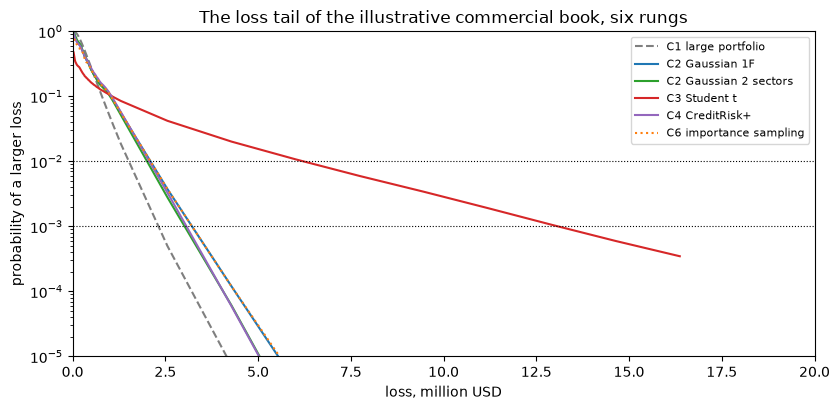

In [6]:
# Draw the exceedance probability of the committed rungs of the commercial book on one logarithmic axis
fig, ax = plt.subplots(figsize=(8.5, 4.2))
styles = (("c1-lhp", "tab:gray", "--", "C1 large portfolio"), ("c2-gaussian-1f", "tab:blue", "-", "C2 Gaussian 1F"),
          ("c2-gaussian-mf", "tab:green", "-", "C2 Gaussian 2 sectors"), ("c3-student-t", "tab:red", "-", "C3 Student t"),
          ("c4-creditrisk-plus", "tab:purple", "-", "C4 CreditRisk+"), ("c6-is-gaussian", "tab:orange", ":", "C6 importance sampling"))
for rid, color, line, label in styles:
    curve = rungs[rid]["distribution"]
    ax.plot(np.array(curve["loss"]) / 1e6, np.maximum(1 - np.array(curve["cdf"]), 1e-9), color=color, linestyle=line, label=label)
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="black", linestyle=":", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlim(0, 20)
ax.set_xlabel("loss, million USD")
ax.set_ylabel("probability of a larger loss")
ax.set_title("The loss tail of the illustrative commercial book, six rungs")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The figure compares the models. One more comparison puts them in proportion: how much capital depends on the choice of model, and how much on the uncertainty of the correlation that every model takes as input. The next cell computes the large-portfolio 99.9% VaR at the ends of the 95% likelihood-ratio interval of the correlation from notebook 02, with the fitted PD, and sets that spread beside the spread among the committed rungs. It also reads the measured size of the interval's estimator on the simulator, from `grid-22.json`, because an interval is only as useful as its coverage.

In [7]:
# Compare the capital spread from the correlation interval with the spread among the models
from riskvalidation.engines.vasicek import lhp_quantile

fit = ci["fit"]["maximum_likelihood"]
lgd = book["lgd_mean"]
scale = book["total_ead"] * lgd
print(f"{'rho':>8s} {'large-portfolio VaR 99.9%':>34s} {'ratio to the fit':>24s}")
points = (("ci_low", fit["rho"]["ci_low"]), ("fit", fit["rho"]["estimate"]), ("ci_high", fit["rho"]["ci_high"]))
by_rho = {label: scale * float(lhp_quantile(0.999, fit["pd"]["estimate"], rho_value)) for label, rho_value in points}
for label, rho_value in points:
    print(f"{rho_value:8.4f} {by_rho[label]:34,.0f} {by_rho[label] / by_rho['fit']:24.3f}   ({label})")
parameter_spread = by_rho["ci_high"] / by_rho["ci_low"]

models_999 = {rid: rungs[rid]["measures"][1]["var"] for rid in ("c1-lhp", "c2-gaussian-1f", "c2-gaussian-mf", "c4-creditrisk-plus", "c5-granularity", "c3-student-t")}
without_t = {k: v for k, v in models_999.items() if k != "c3-student-t"}
print("high over low, correlation interval (same model):", round(parameter_spread, 2))
print("largest over smallest among the five models without the t copula:", round(max(without_t.values()) / min(without_t.values()), 2))
print("largest over smallest among all six models:", round(max(models_999.values()) / min(models_999.values()), 2))
print("measured size of the maximum-likelihood interval test, 22 years:", grid22["impact"]["size_ml"]["value"], "| nominal 0.05")

     rho          large-portfolio VaR 99.9%         ratio to the fit
  0.0382                          1,645,635                    0.716   (ci_low)
  0.0637                          2,298,833                    1.000   (fit)
  0.1158                          3,682,446                    1.602   (ci_high)
high over low, correlation interval (same model): 2.24
largest over smallest among the five models without the t copula: 1.43
largest over smallest among all six models: 5.7
measured size of the maximum-likelihood interval test, 22 years: 0.0525 | nominal 0.05


## Results

- **The ladder reproduces, and the impact figures are quotients of its rows.** The committed ladder holds eight rows, C1 to C6, one of which, the Student t importance sampler, did not run and carries no number. The two analytic rungs recomputed here, C1 and C4, agree with the committed ones to 4e-3 and 5e-3 USD, the rounding of the file (baked by engine 0.7.0, installed 0.8.1). The four impact figures recomputed from the rung rows equal the stored ones: the Student t copula is 4.121813 times the Gaussian copula at 99.9%, the Gaussian copula 1.382005 times the large-portfolio limit, the granularity adjustment 0.00983 of exposure, and the fitted capital 0.335915 of the IRB capital.
- **On one book, five models sit within 43% of each other and one does not.** At 99.9%, relative to the large-portfolio limit (2,298,834 USD), the two-sector Gaussian copula is 1.319, CreditRisk+ 1.339, the one-factor Gaussian copula 1.382, importance sampling 1.394 and the limit plus the granularity adjustment 1.428. The Student t copula is 5.696 times the limit, 13,095,000 USD, and its expected shortfall is 16,000,767 USD against 3,683,187 USD for the Gaussian copula. The tail-dependence assumption is the largest choice of structure in the ladder, larger than the whole spread among the other five models.
- **CreditRisk+ and the Gaussian copula land close together, as Gordy's result leads one to expect, and this is not a test of it.** CreditRisk+ is 0.969 times the Gaussian copula at 99.9% on the commercial book and between 0.928 and 1.000 on the five loan types. The two share the PD and the variance of the default rate (the Gamma variance is matched by moments to the Vasicek default rate), so closeness is partly built in. The dossier records Gordy's statement from the abstract and marks its wording unverified, and this notebook compares one calibration of each family on one set of books.
- **Concentration costs 2.5% to 88% of the large-portfolio VaR, and the adjustment depends on the capital it is given.** The granularity adjustment over the large-portfolio VaR is 0.428 for the commercial book (104 effective names), 0.437 for commercial real estate (50), 0.090 for other consumer (1,250), 0.025 for credit cards (1,667) and 0.878 for residential (595). The residential figure is large because the adjustment takes its capital $K_i$ from the IRB formula at the regulatory correlation (the committed `k_source` is `irb-regulatory-correlation`), while the limit uses the fitted correlation, which for residential is 0.0129 against the IRB 0.15: the ratio mixes two correlations and is not a pure measure of concentration.
- **The correlation input matters more than the choice among the five models, and less than the tail dependence.** The large-portfolio 99.9% VaR at the ends of the 95% likelihood-ratio interval of the correlation is 1,645,635 and 3,682,446 USD, 0.716 and 1.602 times the fit, a spread of 2.24 from one end to the other with the model held fixed. Among the five models without the t copula the spread is 1.43; with the t copula it is 5.7. The estimator behind the interval has a measured size of 0.0525 against 0.05 on the simulator at 22 years, so the interval is honest on independent years, and notebook 02 showed that real years are strongly autocorrelated.
- **The open-source gap, with its limits.** The dossier found no maintained, permissively licensed Python implementation of CreditMetrics or CreditRisk+ in a search dated 2026-10-04. That is an absence finding bounded by one search, and this notebook cannot widen it. What the notebook shows is the other side: a permissively licensed engine whose analytic rungs reproduce a committed ladder and whose Monte Carlo rungs agree with them within their standard errors (notebooks 03 to 05).

What this notebook does not show: CreditMetrics in migration mode (not implemented), the sector-concentration models of the literature (not run), heavy-tailed importance sampling (the research found no twist to implement), or which of the models a bank should adopt. The comparison is default-mode on illustrative books.

## Summary

- The literature the research found has structural models (CreditMetrics, Gaussian and t copulas), the actuarial CreditRisk+, the large-portfolio limit with its granularity adjustment and rare-event simulation; Contraste runs all of them except CreditMetrics' migration mode, and it records that the Student t importance sampler did not run.
- On one book and one calibration, five models sit within 43% of each other at 99.9%, and the Student t copula is 5.7 times the limit: tail dependence is the largest structural choice.
- CreditRisk+ and the Gaussian copula agree within 7% on five loan types, partly by construction; this is consistent with Gordy's equivalence and is not a test of it.
- The correlation input moves capital by a factor of 2.2 across its 95% interval, more than the choice among the five models, and the interval's size is 0.0525 on independent years.
- The open-source gap is an absence finding from a search dated 2026-10-04; Contraste answers it with a permissively licensed engine checked against analytic anchors.

**What to try next.** Recompute the parameter spread for credit cards or residential from their own intervals and compare it with their model spread. Then open notebook 08 for the claim this topic demonstrates.

## References

- Gordy, M. B. (2000), A comparative anatomy of credit risk models, Journal of Banking and Finance 24(1-2):119-149. https://doi.org/10.1016/S0378-4266(99)00054-0
- Gupton, G. M., Finger, C. C. and Bhatia, M. (1997), CreditMetrics Technical Document, J.P. Morgan, reissued by RiskMetrics Group (2007) and hosted by MSCI (authors as usually cited). https://www.msci.com/documents/10199/93396227-d449-4229-9143-24a94dab122f
- Li, D. X. (2000), On default correlation: a copula function approach, Journal of Fixed Income 9(4):43-54. https://doi.org/10.3905/jfi.2000.319253
- Frey, R. and McNeil, A. J. (2003), Dependent defaults in models of portfolio credit risk, Journal of Risk 6(1):59-92. https://doi.org/10.21314/jor.2003.089
- Demarta, S. and McNeil, A. J. (2005), The t copula and related copulas, International Statistical Review 73(1):111-129. https://doi.org/10.1111/j.1751-5823.2005.tb00254.x
- Haaf, H., Reiss, O. and Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. and Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Glasserman, P. and Li, J. (2005), Importance sampling for portfolio credit risk, Management Science 51(11):1643-1656. https://doi.org/10.1287/mnsc.1050.0415
- Glasserman, P., Heidelberger, P. and Shahabuddin, P. (2002), Portfolio value-at-risk with heavy-tailed risk factors, Mathematical Finance 12(3):239-269. https://doi.org/10.1111/1467-9965.00141
- BCBS (2006), Studies on credit risk concentration: an overview of the issues and a synopsis of the results from the Research Task Force project, Working Paper No. 15. https://www.bis.org/publ/bcbs_wp15.pdf
- Dullmann, K. and Masschelein, N. (2007), A tractable model to measure sector concentration risk in credit portfolios, Journal of Financial Services Research 32(1-2):55-79. https://doi.org/10.1007/s10693-007-0014-3
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Credit Suisse First Boston (1997), CreditRisk+: A Credit Risk Management Framework: not accessed by the research (UNVERIFIED primary).
- Pykhtin, M. (2004), Multi-factor adjustment, Risk 17(3): bibliographic details not verified by the research (UNVERIFIED).
- Persisted research dossier 04 of this product (credit-risk models, state of the art), section H, in particular H.3 to H.8; the open-source search is dated 2026-10-04.
- Open Risk portfolioAnalytics (GPL-2.0), https://github.com/open-risk/portfolioAnalytics, named by the dossier among the implementations found.